# BAN 8101 Predictive Analytics
## Week 4 Lecture Note: How Logistic Regression Works

### Big Idea

Logistic regression is a **classification model**.

It begins by computing a linear score:

$\
z=\mathbf{w}^T\mathbf{x}+b
\$

and converts that score into a probability using a non-linear function(sigmoid function):

$
\sigma(z)=\frac{1}{1+e^{-z}}
\$

The resulting probability can then be converted into a class using a threshold.


# 1. Binary Classification Setup

Suppose we have \(n\) observations and \(m\) predictors:


$$
X =
\begin{bmatrix}
x_{11} & x_{12} & \cdots & x_{1m} \\
x_{21} & x_{22} & \cdots & x_{2m} \\
\vdots & \vdots & \ddots & \vdots \\
x_{n1} & x_{n2} & \cdots & x_{nm}
\end{bmatrix}
$$

where:

- \(n\) = number of observations
- \(m\) = number of predictors
- each row = one observation
- each column = one predictor

The target is binary:

$
y_i\in\{0,1\}
$

For customer churn:

$
y_i=
\begin{cases}
0 & \text{customer stays}\\
1 & \text{customer churns}
\end{cases}
$

# 2. Step 1 — Compute a Linear Score

For one observation:

$
z_i=b+w_1x_{i1}+w_2x_{i2}+\cdots+w_mx_{im}
$

or:

$
z_i=\mathbf{w}^T\mathbf{x}_i+b
$

where:

- $\mathbf{x}_i$ = predictors for observation \(i\)
- $\mathbf{w}$ = coefficient vector
- $b$ = intercept
- $z_i$ = linear score

At this stage, $z$ is **not a probability**.

It can take any real value.

## Example: Computing \(z\)

Assume:

$
b=-0.5,\quad w_1=0.8,\quad w_2=-0.03
$

where:

- \(x_1\) = support tickets
- \(x_2\) = tenure in months

For a customer with:

$
x_1=4,\quad x_2=12
$

we compute:

$
z=-0.5+(0.8)(4)+(-0.03)(12)
$

In [1]:
b = -0.5
w1 = 0.8
w2 = -0.03

support_tickets = 4
tenure_months = 12

z = b + w1 * support_tickets + w2 * tenure_months
print("Linear score z =", round(z, 3))

Linear score z = 2.34


# 3. Step 2 — Apply the Sigmoid Function

The sigmoid function converts \(z\) into a probability:

$$
\Large
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Therefore:

$
P(y=1\mid X)=\sigma(z)
$

and:

$
P(y=0\mid X)=1-\sigma(z)
$

Properties:

- $z\to+\infty \Rightarrow \sigma(z)\to1$
- $z\to-\infty \Rightarrow \sigma(z)\to0$
- $z=0 \Rightarrow \sigma(z)=0.5$

In [2]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

p = sigmoid(z)

print("z =", round(z, 3))
print("P(y=1) =", round(p, 3))
print("P(y=0) =", round(1-p, 3))

z = 2.34
P(y=1) = 0.912
P(y=0) = 0.088


## Visualizing the Sigmoid Function

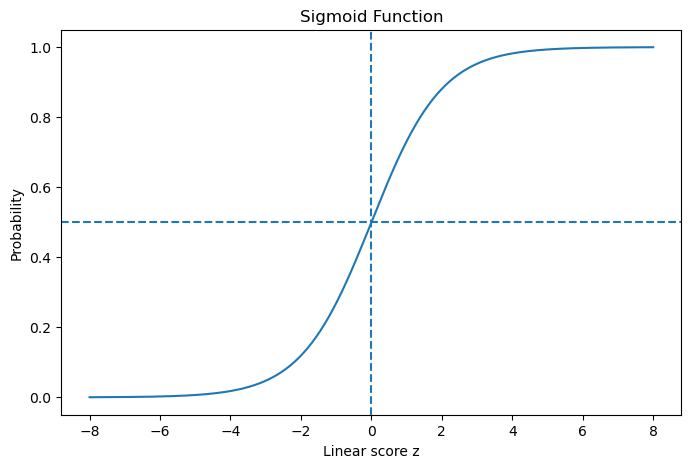

In [3]:
import matplotlib.pyplot as plt

z_values = np.linspace(-8, 8, 400)
p_values = sigmoid(z_values)

plt.figure(figsize=(8,5))
plt.plot(z_values, p_values)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("Linear score z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.show()

# 4. Step 3 — Convert Probability into a Class

With threshold 0.50:

$$
\hat y=
\begin{cases}
1 & \text{if }P(y=1)\ge0.50\\
0 & \text{if }P(y=1)<0.50
\end{cases}
$$

The threshold is a **decision rule**.

In [ ]:
threshold = 0.50
predicted_class = int(p >= threshold)

print("Predicted probability =", round(p, 3))
print("Threshold =", threshold)
print("Predicted class =", predicted_class)

# 5. Odds and Log-Odds

Suppose the probability that an observation belongs to Class 1 is:

$$
p=P(y=1)
$$

For example, in our customer churn problem:

- \(y=1\) means the customer churns
- \(y=0\) means the customer stays

If the model estimates:

$$
P(y=1)=0.80
$$

then the probability of the opposite outcome is:

$$
P(y=0)=1-0.80=0.20
$$

## Probability vs. Odds

Probability describes the chance that an event occurs out of all possible outcomes.

Odds compare the probability that the event **does occur** with the probability that it **does not occur**.

The odds are defined as:

$$
\text{Odds}=\frac{p}{1-p}
$$

If:

$$
p=0.80
$$

then:

$$
\text{Odds}
=
\frac{0.80}{1-0.80}
=
\frac{0.80}{0.20}
=
4
$$

This can be interpreted as:

> The odds are 4 to 1 in favor of the event occurring.

In our customer churn example, this means that according to the model, the customer is four times as likely to churn as to stay.

Notice that **probability and odds are not the same thing**.

For example:

| Probability | Odds |
|---:|---:|
| 0.20 | 0.25 |
| 0.50 | 1.00 |
| 0.80 | 4.00 |
| 0.90 | 9.00 |

When the probability is 0.50, the odds are:

$$
\frac{0.50}{0.50}=1
$$

which means the two outcomes are equally likely.

---

## Why Do We Need Log-Odds?

The odds:

$$
\frac{p}{1-p}
$$

can range from:

$$
0 \text{ to } +\infty
$$

However, a linear model such as:

$$
\mathbf{w}^T\mathbf{x}+b
$$

can produce values anywhere from:

$$
-\infty \text{ to } +\infty
$$

Therefore, odds themselves do not match the range of a linear model very well.

To solve this problem, logistic regression takes the **natural logarithm of the odds**.

This quantity is called the **log-odds** or **logit**:

$$
\text{logit}(p)
=
\log\left(\frac{p}{1-p}\right)
$$

The log-odds can take any value from:

$$
-\infty \text{ to } +\infty
$$

This makes the log-odds suitable for modeling with a linear equation.

---

## The Key Logistic Regression Assumption

Logistic regression assumes that the **log-odds of the positive outcome** can be expressed as a linear combination of the predictors:

$$
\log\left(\frac{p}{1-p}\right)
=
\mathbf{w}^T\mathbf{x}+b
$$

or equivalently:

$$
\log\left(\frac{p}{1-p}\right)
=
b+w_1x_1+w_2x_2+\cdots+w_mx_m
$$

This is the most important equation behind logistic regression.

The right-hand side looks just like a linear regression model:

$$
b+w_1x_1+w_2x_2+\cdots+w_mx_m
$$

But logistic regression does **not** model \(y\) directly.

Instead, it models:

$$
\log\left(\frac{p}{1-p}\right)
$$

the **log-odds of belonging to Class 1**.

---

## Example

Suppose our fitted logistic regression model gives:

$$
\mathbf{w}^T\mathbf{x}+b=1.386
$$

Then:

$$
\log\left(\frac{p}{1-p}\right)=1.386
$$

To convert log-odds back into odds, exponentiate both sides:

$$
\frac{p}{1-p}=e^{1.386}\approx4
$$

So the odds are approximately:

$$
4:1
$$

which corresponds to a probability of:

$$
p=\frac{4}{1+4}=0.80
$$

Therefore:

$$
P(y=1)\approx0.80
$$

---

## Why This Matters

This explains why logistic regression is called **regression**, even though it is used for classification.

The model is performing a linear regression-like calculation on the **log-odds**:

$$
\boxed{
\log\left(\frac{p}{1-p}\right)
=
\mathbf{w}^T\mathbf{x}+b
}
$$

The process can be summarized as:

**Predictors**

$$
X
$$

↓

**Linear combination**

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

↓

**Interpret \(z\) as log-odds**

$$
z=
\log\left(\frac{p}{1-p}\right)
$$

↓

**Convert log-odds into probability**

$$
p=\frac{1}{1+e^{-z}}
$$

↓

**Apply a classification threshold**

$$
p\ge0.50 \Rightarrow \hat y=1
$$

In [4]:
p_example = 0.75
odds = p_example / (1-p_example)
log_odds = np.log(odds)

print("Probability =", p_example)
print("Odds =", round(odds, 3))
print("Log-odds =", round(log_odds, 3))

Probability = 0.75
Odds = 3.0
Log-odds = 1.099


# 6. From Log-Odds to Probability

In the previous section, we established that logistic regression models the **log-odds** of the positive class as a linear function of the predictors.

That is:

$$
\log\left(\frac{p}{1-p}\right)=z
$$

where:

- \(p=P(y=1)\)
- \(1-p=P(y=0)\)
- $z=\mathbf{w}^T\mathbf{x}+b$

The quantity \(z\) can take any real value, from very negative to very positive.

However, for classification, we usually want something much easier to interpret:

> **a probability between 0 and 1**

So the next step is to convert the log-odds back into a probability.

---

## Step 1 — Remove the Logarithm

Start with:

$$
\log\left(\frac{p}{1-p}\right)=z
$$

Because the natural logarithm and the exponential function are inverses of each other, we can exponentiate both sides:

$$
\frac{p}{1-p}=e^z
$$

Now the left-hand side is no longer log-odds.

It is simply the **odds** of the positive class.

---

## Step 2 — Solve for \(p\)

We now want to isolate \(p\).

Starting from:

$$
\frac{p}{1-p}=e^z
$$

multiply both sides by \(1-p\):

$$
p=e^z(1-p)
$$

Expand the right-hand side:

$$
p=e^z-e^zp
$$

Move the terms involving \(p\) to the same side:

$$
p+e^zp=e^z
$$

Factor out \(p\):

$$
p(1+e^z)=e^z
$$

Finally:

$$
p=\frac{e^z}{1+e^z}
$$

This gives us the probability directly.

---

## Step 3 — Rewrite the Equation

The expression:

$$
p=\frac{e^z}{1+e^z}
$$

is mathematically equivalent to:

$$
p=\frac{1}{1+e^{-z}}
$$

This second form is the **sigmoid function** that we introduced earlier.

So:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

and:

$$
P(y=1)=\sigma(z)
$$

---

## Step 4 — Substitute the Linear Model

Recall that:

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

Therefore:

$$
P(y=1\mid X)
=
\frac{1}
{1+e^{-(\mathbf{w}^T\mathbf{x}+b)}}
$$

This is the final probability equation for logistic regression.

---

## What Does This Mean?

The model performs two major steps.

First, it combines the predictors linearly:

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

Then it passes that value through the sigmoid function:

$$
p=\frac{1}{1+e^{-z}}
$$

This guarantees that the final output is always between:

$$
0 \le p \le 1
$$

Therefore, the output can be interpreted as a probability.

---

## Example

Suppose:

$$
z=2
$$

Then:

$$
p=\frac{1}{1+e^{-2}}
$$

which is approximately:

$$
p\approx0.881
$$

So the model estimates:

$$
P(y=1)\approx88.1\%
$$

If our classification threshold is 0.50:

$$
0.881 > 0.50
$$

therefore:

$$
\hat y=1
$$

---

## The Complete Transformation

The whole process can be summarized as:

**Predictors**

$$
X
$$

↓

**Linear score**

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

↓

**Sigmoid transformation**

$$
p=\frac{1}{1+e^{-z}}
$$

↓

**Predicted probability**

$$
P(y=1)=p
$$

↓

**Classification threshold**

$$
p\ge0.50 \Rightarrow \hat y=1
$$

# 7. Interpreting Coefficients

A coefficient $w_j$ represents the change in **log-odds** associated with a one-unit increase in predictor $x_j$, holding other predictors constant.

Because log-odds are difficult to interpret, we often exponentiate:

$$
e^{w_j}
$$

This is the **odds ratio**.

- Odds ratio > 1 → higher odds of class 1
- Odds ratio < 1 → lower odds of class 1
- Odds ratio = 1 → no change in odds

In [ ]:
coef = 0.40
odds_ratio = np.exp(coef)

print("Coefficient =", coef)
print("Odds ratio =", round(odds_ratio, 3))

# 8. Maximum Likelihood Estimation

The model must estimate:

$$
w_1,w_2,\ldots,w_m,b
$$

Logistic regression typically uses:

## Maximum Likelihood Estimation (MLE)

The idea is:

> Choose the coefficients that make the observed outcomes as likely as possible.

# 9. Likelihood Function

For observation \(i\), let:

$$
p_i=P(y_i=1\mid x_i)
$$
Then:

$$
P(y_i\mid x_i) = p_i^{y_i}(1-p_i)^{1-y_i}
$$

For all observations:

$$
L(\mathbf{w},b) = \prod_{i=1}^{n}p_i^{y_i}(1-p_i)^{1-y_i}
$$

The fitted model chooses $\mathbf{w}$ and $b$ to maximize this likelihood.

# 10. Log-Likelihood

Because products of many probabilities can become extremely small, we use the log-likelihood:

$$
\ell(\mathbf{w},b)
=
\sum_{i=1}^{n}
\left[
y_i\log(p_i)
+
(1-y_i)\log(1-p_i)
\right]
$$

Intuition:

- if \(y_i=1\), we want \(p_i\) close to 1
- if \(y_i=0\), we want \(p_i\) close to 0

# 11. Gradient — Briefly

For coefficient $w_j$:

$$
\frac{\partial \ell}{\partial w_j}
=
\sum_{i=1}^{n}(y_i-p_i)x_{ij}
$$

Conceptually, the optimizer adjusts coefficients based on the difference between:

$$
y_i
$$

and:

$$
p_i
$$

You do **not** need to calculate these gradients manually in this course.

# 12. Terminology Summary

| Term | Meaning |
|---|---|
| Independent variables | Predictor variables |
| Dependent variable | Target variable |
| Binary target | Target with two outcomes, usually 0 and 1 |
| Linear score | $z=\mathbf{w}^T\mathbf{x}+b$ |
| Sigmoid function | Converts \(z\) into a probability |
| Probability | Estimated likelihood that \(y=1\) |
| Odds | $p/(1-p)$ |
| Log-odds / Logit | $\log[p/(1-p)]$ |
| Coefficient | Effect of a predictor on log-odds |
| Odds ratio | $e^{w_j}$ |
| Intercept | Baseline log-odds when predictors are zero |
| Maximum Likelihood Estimation | Method used to estimate coefficients |
| Threshold | Rule used to convert probability into class |

# 13. Full Logistic Regression Workflow

$$
X
$$

↓

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

↓

$$
p=\sigma(z)
$$

↓

$$
P(y=1)=p
$$

↓

**Apply threshold**

↓

$$
\hat y\in\{0,1\}
$$

In plain language:

**Predictors → Linear Score → Probability → Threshold → Class**

# 15. Mini Numerical Example

Suppose:

$$
z=-1.2+0.5x_1-0.04x_2
$$

where:

- $x_1$ = support tickets
- $x_2$ = tenure in months

For:

$$
x_1=3,\quad x_2=10
$$

calculate:

1. $z$
2. predicted probability
3. predicted class at threshold 0.50

In [ ]:
b = -1.2
w_tickets = 0.5
w_tenure = -0.04

tickets = 3
tenure = 10

z = b + w_tickets * tickets + w_tenure * tenure
p = sigmoid(z)
pred = int(p >= 0.50)

print("z =", round(z, 3))
print("Predicted probability of churn =", round(p, 3))
print("Predicted class =", pred)

# 16. Discussion Questions

This is the discussion topic for this week. 

1. Why can't the raw linear score \(z\) be used directly as a probability?
2. What does the sigmoid function accomplish?
3. What is the difference between probability and odds?
4. Why is logistic regression still called a regression model?
5. What does a positive coefficient mean?
6. What does an odds ratio greater than 1 mean?
7. Why do we use maximum likelihood estimation?
8. What is the difference between `predict_proba()` and `predict()`?
9. Why might a threshold other than 0.50 be appropriate?

# 17. Theory Takeaways

Logistic regression:

1. combines predictors into a linear score
2. converts that score into a probability with the sigmoid function
3. estimates coefficients using maximum likelihood
4. converts probabilities into classes using a threshold

Core equations:

$$
z=\mathbf{w}^T\mathbf{x}+b
$$

$$
P(y=1\mid X)=\frac{1}{1+e^{-z}}
$$

$$
\log\left(\frac{p}{1-p}\right)=\mathbf{w}^T\mathbf{x}+b
$$

Next, we apply these ideas to customer churn and evaluate the classifier using:

- confusion matrix
- accuracy
- precision
- recall
- F1 score
- ROC-AUC
- threshold analysis